In [2]:
# %%
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as spr
from scipy.sparse.linalg import inv
from scipy.interpolate import RegularGridInterpolator, griddata
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates


import cmocean
from netCDF4 import Dataset
#from datetime import date, timedelta
import re
import xarray as xr
#from xarray.coders import CFDatetimeCoder

## . . For animation
from matplotlib import animation
import matplotlib.ticker as ticker
import matplotlib.transforms as mtrans
from IPython.display import HTML, Image
import geopandas
import rioxarray as rio
from shapely.geometry import mapping, shape
import os
import gc
import pandas as pd
from scipy.interpolate import interp1d
import copy
from pyproj import Transformer


In [3]:
path = "/Users/rohaizharis/Desktop/Research/Mines/Chapter 1/GRL26"

# %%
IMBIE = geopandas.read_file(path+"/Inputs/ANT_Basins_IMBIE2_v1.6/ANT_Basins_IMBIE2_v1.6.shp", crs="epsg:3031")
scripps = geopandas.read_file(path+"/Inputs/scripps_GL/scripps_antarctica_polygons_v1.shp", crs="epsg:3031")
scripps_gl = scripps.loc[scripps['Id'].astype(int) == 1]
ssb = rio.open_rasterio(path+"/Inputs/AntarcticBasins_BedTypeCode.tif")

df = pd.read_parquet(path + "/Outputs/projection_data_unmasked.parquet")


/Users/rohaizharis/miniforge3/envs/1d_model/lib/python3.12/site-packages/pyogrio/raw.py:198: RuntimeWarning: driver ESRI Shapefile does not support open option CRS
  return ogr_read(
/Users/rohaizharis/miniforge3/envs/1d_model/lib/python3.12/site-packages/pyogrio/raw.py:198: RuntimeWarning: driver ESRI Shapefile does not support open option CRS
  return ogr_read(


In [4]:
model_names = ["DOE_MALI",
               "ILTS_SICOPOLIS",
               "NCAR_CISM2",
               "PIK_PISM",
               "UCM_Yelmo",
               "ULB_fETISH-KoriBU1",
               "UTAS_ElmerIce",
               "VUW_PISM1"]
exp_names = ["expAE02", "expAE03", "expAE04", "expAE05", "expAE10", "ctrlAE"]
color_arr = ["#CB4700","#F9845D","#EA0D18","#910101","C0","black"]

In [5]:
def plot_proj(ax, bas):
    basin_df = df[
        (df["basin"] == bas) &
        (df["array_type"] == "gw")
    ]

    for exp_name, color in zip(exp_names, color_arr):
        mean_frac = basin_df[basin_df["exp_name"] == exp_name].groupby("timestep")["frac"].mean().values
        ax.plot(time, mean_frac, "-", color=color, lw=1, label=exp_name)
        #ax.scatter(time, mean_frac, s=0.2,color=color, marker='.',label=exp_name)


    plt.title('Basin '+ IMBIE.loc[bas].Subregion, fontsize = 10, y = 0.85,x=0.35)
    ax.set_ylabel("Fraction", fontsize = 8)
    ax.set_xlabel("Year", fontsize = 8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1)
    ax.spines['left'].set_linewidth(1)
    plt.ylim([-0.2,0.2])
    plt.xlim([time[0],time[-1]])
    plt.xticks(rotation=45, ha='right', fontsize=8)
    ax.tick_params(axis='x', length=6, width=1, pad=-1)
    trans = mtrans.Affine2D().translate(10, 0) # Move 10 points right
    for t in ax.get_xticklabels():
        t.set_transform(t.get_transform() + trans)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.xticks([np.datetime64('2050'),np.datetime64('2100'),np.datetime64('2150'),np.datetime64('2200'),np.datetime64('2250'),np.datetime64('2300')])
    print('Basin '+ str(IMBIE.loc[bas].Subregion))

Basin Jpp-K
Basin K-A
Basin A-Ap
Basin Ap-B
Basin B-C
Basin C-Cp
Basin Cp-D
Basin D-Dp
Basin Dp-E
Basin E-Ep
Basin Ep-F
Basin F-G
Basin G-H
Basin H-Hp
Basin J-Jpp


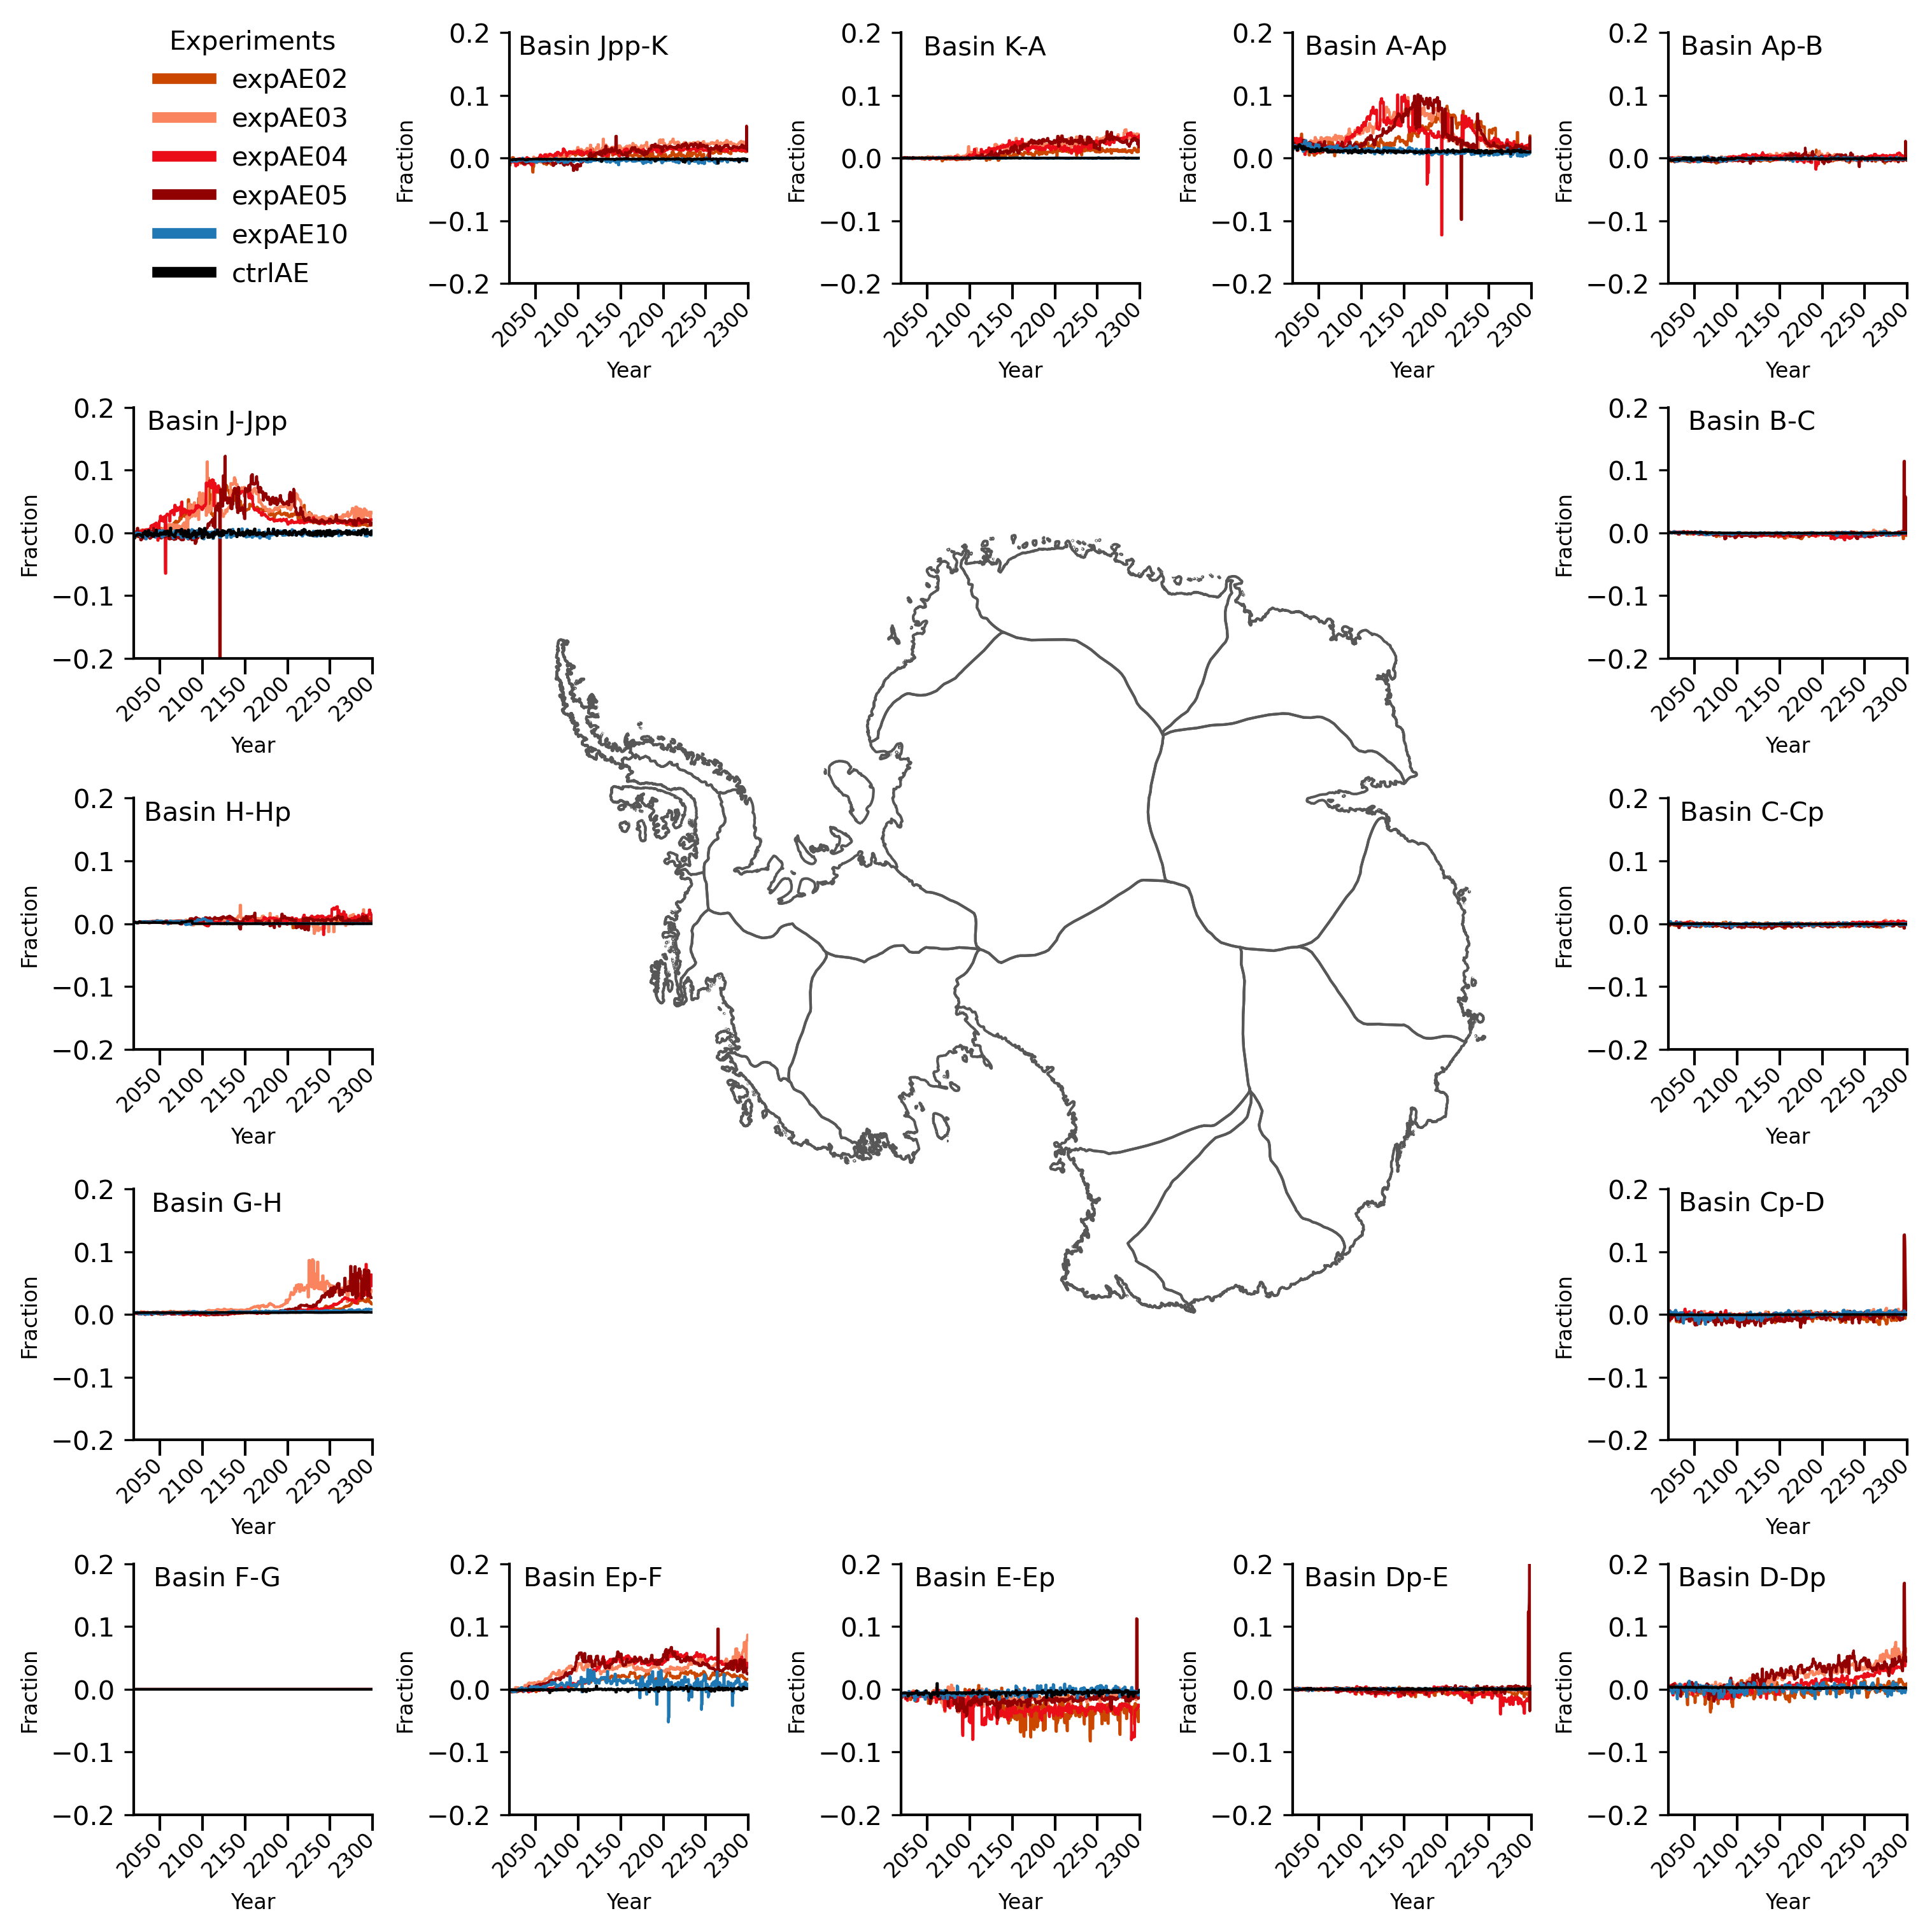

In [ ]:
fig = plt.figure(figsize=(10,10), dpi=300,constrained_layout=True)

spec = gridspec.GridSpec(ncols=5, nrows=5, figure=fig)
ax_AA = fig.add_subplot(spec[1:-1,1:-1])
IMBIE.plot(ax=ax_AA, color="none", edgecolor='#575757',facecolor="none",linewidth=1)
plt.axis('off')
time = np.arange(np.datetime64("2019-01-01"), np.datetime64("2300-01-05"), np.timedelta64(65,'D'))

ax_jppk = fig.add_subplot(spec[0,1])
plot_proj(ax_jppk,8)

ax_ka = fig.add_subplot(spec[0,2])
plot_proj(ax_ka,13)

ax_aap = fig.add_subplot(spec[0,3])
plot_proj(ax_aap,7)

ax_apb = fig.add_subplot(spec[0,4])
plot_proj(ax_apb,11)

ax_bc = fig.add_subplot(spec[1,4])
plot_proj(ax_bc,6)

ax_ccp = fig.add_subplot(spec[2,4])
plot_proj(ax_ccp,12)

ax_cpd = fig.add_subplot(spec[3,4])
plot_proj(ax_cpd,5)

ax_ddp = fig.add_subplot(spec[4,4])
plot_proj(ax_ddp,4)

ax_dpe = fig.add_subplot(spec[4,3])
plot_proj(ax_dpe,10)

ax_eep = fig.add_subplot(spec[4,2])
plot_proj(ax_eep,3)

ax_epf = fig.add_subplot(spec[4,1])
plot_proj(ax_epf,18)

ax_fg = fig.add_subplot(spec[4,0])
plot_proj(ax_fg,2)

ax_gh = fig.add_subplot(spec[3,0])
plot_proj(ax_gh,9)

ax_hhp = fig.add_subplot(spec[2,0])
plot_proj(ax_hhp,1)

ax_jjpp = fig.add_subplot(spec[1,0])
plot_proj(ax_jjpp,14)

ax_legend = fig.add_subplot(spec[0, 0])
ax_legend.axis("off")
handles, labels = ax_jppk.get_legend_handles_labels()

leg = ax_legend.legend(
    handles, labels,
    loc="center",           
    frameon=False,          
    fontsize=10,
    title="Experiments"
)
for line in leg.get_lines():
    line.set_linewidth(4.0)

#plt.savefig("fig3_12oct.png")


In [ ]:
#Code snippet that finds peak exfiltration contributions and timings by basin and experiment,

basin_df = df[
        (df["basin"] == 7) &
        (df["array_type"] == "gw") & 
        (df["exp_name"] == "expAE05")
    ]

mean_frac = basin_df.groupby("timestep")["frac"].mean()
max_idx = mean_frac.idxmax()
print(time[max_idx])
print(mean_frac[max_idx]*100)

2166-05-10
10.126612645462208
